# LSTM

Red neuronal recurrente con estructura de codificador y decodificador (Sutskever et al., 2014) y
celdas LSTM (Hochreiter y Schmidhuber, 1997). A diferencia de SARIMAX y XGBoost, una sola red
pronostica a la vez los 168 precios de la semana: 7 días de 24 horas.

La red se entrenó en Colab con GPU, en `6c_lstm_seleccion.ipynb` (selección de variables) y
`6d_lstm_busqueda_y_test.ipynb` (hiperparámetros y test), los dos en la raíz del repositorio. Este notebook no entrena nada: arma la
red con la configuración final para mostrar su estructura y lee los resultados guardados en
`datos/resultados/modelo_lstm_bloques/`.

In [1]:
import os

# en Colab la red corrió con TensorFlow; aquí Keras usa PyTorch y la red es la misma
os.environ["KERAS_BACKEND"] = "torch"
import keras
from keras import layers

In [2]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# pandas 2.3 con numpy 2.5 avisa por una unidad interna de las fechas; no cambia nada
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

RAIZ = Path("datos")
PANELES = RAIZ / "paneles"
XGB = RAIZ / "resultados" / "modelo_xgboost"
SAR = RAIZ / "resultados" / "modelo_sarimax"
LSTM = RAIZ / "resultados" / "modelo_lstm_bloques"
HS = list(range(3, 10))

COLOR = {"precio real": "#2a78d6", "SARIMAX": "#1baf7a", "XGBoost": "#eb6834", "LSTM": "#eda100",
         "ingenuo del día": "#898781", "ingenuo semanal": "#c3c2b7"}
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.grid": True,
                     "grid.color": "#e5e4df", "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 11,
                     "legend.frameon": False})
pd.set_option("display.precision", 3)

## 1. Datos

Cada día se resume en un vector: las 24 horas del logaritmo del precio, las 24 horas de cada
variable horaria, un valor por cada variable diaria y el calendario del día (día de la semana y
festivo). Todo está alineado con el día del pronóstico, $R = t + 2$: en la fila del día $t$ está lo
que ya se había publicado en $R$. Así la red puede usar, por ejemplo, el despacho programado para
el día $R$, que XM publica antes que el precio de ese día.

El objetivo es el mismo de los otros modelos, $y_h = \ln P(t+h,H) - \ln P(t,H)$, para $h = 3$ a
$9$ y las 24 horas.

In [3]:
info = pd.read_csv(PANELES / "panel_lstm_bloques_variables.csv").set_index("variable")
panel = pd.read_csv(PANELES / "panel_lstm_bloques.csv.gz", parse_dates=["fecha"])
panel = panel.sort_values(["fecha", "hora"]).reset_index(drop=True)
assert (panel.groupby("fecha").size() == 24).all()

f = pd.DatetimeIndex(panel["fecha"].drop_duplicates())
n_dias = len(f)
dia = panel.iloc[::24].reset_index(drop=True)
I0 = int(np.searchsorted(f, pd.Timestamp("2015-03-01")))


def por_dia(col):
    return panel[col].to_numpy(np.float32).reshape(n_dias, 24)


def calendario(dia_semana, festivo):
    return np.column_stack([np.eye(7, dtype=np.float32)[dia_semana], festivo.astype(np.float32)])


LP = por_dia("lp")
Y = np.stack([por_dia(f"y_h{h}") for h in HS], axis=1)
CAL_T = calendario(dia["dia_semana"].to_numpy(), dia["es_festivo"].to_numpy())
CAL_K = np.stack([calendario(dia[f"dia_semana_k{k}"].to_numpy(), dia[f"es_festivo_k{k}"].to_numpy())
                  for k in range(1, 8)], axis=1)

print(f"{n_dias} días, del {f[0].date()} al {f[-1].date()}")
print("precio:", LP.shape, "| objetivo:", Y.shape, "| calendario de los 7 días pronosticados:", CAL_K.shape)

4300 días, del 2015-01-01 al 2026-10-09
precio: (4300, 24) | objetivo: (4300, 7, 24) | calendario de los 7 días pronosticados: (4300, 7, 8)


## 2. Bloques de variables

Las 136 variables del panel se agruparon en bloques según lo que dicen del mercado y cuándo se
publican. El precio (bloque 1) y el calendario (bloque 2) siempre entran. Los bloques 3 a 6 se
probaron uno por uno. Las demás variables solo se usaron en una prueba de control con todas.

In [4]:
en_bloque = info[info["bloque"] > 0]
bloques = en_bloque.groupby(["bloque", "nombre_bloque"]).apply(
    lambda g: pd.Series({"variables": len(g), "cuáles": ", ".join(g.index)}), include_groups=False)
pd.set_option("display.max_colwidth", 120)
bloques

,,variables,cuáles
bloque,nombre_bloque,,
3,despacho de hoy,4,"cmg_despacho, disp_decl_hoy_rel, cmg_hoy_vs_precio, frac_termica_prog"
4,estado hidrológico,5,"brecha_escasez, presion_hidro_horaria, aportes_media_hist, volumen_util_pct, dias_autonomia"
5,despacho de ayer,3,"redespacho_vs_programa, cmg_redespacho, error_cmg_despacho"
6,clima que viene,4,"lluvia_anom_acum30, nino34_anom, oni, pred_deficit"


El bloque 3 sale del despacho programado que XM publica el día anterior: costo marginal del
despacho, disponibilidad declarada y fracción térmica programada. El bloque 4 resume el estado
hidrológico: embalses, aportes y su relación con la demanda. El 5 compara lo que pasó ayer con lo
programado y el 6 trae indicadores de clima (El Niño, anomalías de lluvia y pronóstico del IDEAM).

## 3. La red

- El codificador lee los últimos 28 días. Una capa densa reduce primero el vector de cada día a 64
  números, así la red tiene casi el mismo tamaño con cualquier conjunto de variables.
- El decodificador arranca con el estado final del codificador y da 7 pasos, uno por día de la
  semana pronosticada. En cada paso recibe el día de la semana y el festivo de ese día, y entrega
  sus 24 horas.
- La pérdida es el MSE, porque el criterio de la tesis es el RMSE en logaritmo.

Las entradas se estandarizan con la media y la desviación de los días de entrenamiento y se
recortan en $\pm 8$ desviaciones. Estas son las funciones de `6d_lstm_busqueda_y_test.ipynb`:

In [5]:
def entradas(variables, hasta):
    # vector de cada día, estandarizado con los días de entrenamiento (hasta el índice `hasta`)
    partes = [LP] + [por_dia(v) if info.loc[v, "tipo"] == "horaria" else por_dia(v)[:, :1]
                     for v in variables]
    M = np.hstack(partes)
    ref = M[I0:hasta + 1]
    M = np.clip((M - ref.mean(axis=0)) / (ref.std(axis=0) + 1e-6), -8, 8)
    return np.hstack([M, CAL_T]).astype(np.float32)


def ventanas(M, idx, ventana):
    return M[idx[:, None] - np.arange(ventana - 1, -1, -1)]


def construir(n_entradas, c):
    historia = keras.Input((c["ventana"], n_entradas))
    semana = keras.Input((len(HS), CAL_K.shape[2]))
    x = layers.Dense(c["densa"], activation="relu")(historia)
    x = layers.Dropout(c["dropout"])(x)
    estados = []
    for _ in range(c["capas"]):
        x, h, s = layers.LSTM(c["unidades"], return_sequences=True, return_state=True)(x)
        estados.append([h, s])
    y = semana
    for estado in estados:
        y = layers.LSTM(c["unidades"], return_sequences=True)(y, initial_state=estado)
    y = layers.Dense(24)(layers.Dropout(c["dropout"])(y))
    modelo = keras.Model([historia, semana], y)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=c["tasa"]), loss="mse")
    return modelo

La red final, con la configuración guardada. Para pronosticar desde el 31 de diciembre de 2022 la
red recibe una matriz de 28 días por 179 números (24 del precio, 24 por cada una de las 6
variables horarias, 1 por cada una de las 3 diarias y 8 del calendario) y el calendario de los 7
días que va a pronosticar.

In [6]:
cfg = json.load(open(LSTM / "configuracion_final.json", encoding="utf-8"))
print({k: cfg[k] for k in ["capas", "unidades", "densa", "dropout", "tasa", "lote", "ventana", "epocas", "semillas"]})
print("variables:", ", ".join(cfg["variables"]))

i = int(np.flatnonzero(f == pd.Timestamp("2022-12-31"))[0])
M = entradas(cfg["variables"], i)
X = [ventanas(M, np.array([i]), cfg["ventana"]), CAL_K[[i]]]
print("entradas para un día:", X[0].shape, X[1].shape)

red = construir(M.shape[1], cfg)
capas = []
for capa in red.layers:
    salida = capa.output if isinstance(capa.output, list) else [capa.output]
    capas.append({"capa": capa.name, "tipo": type(capa).__name__,
                  "forma de la salida": ", ".join(str(tuple(s.shape)) for s in salida),
                  "parámetros": capa.count_params()})
print(f"{red.count_params():,} parámetros en total")
pd.DataFrame(capas)

{'capas': 1, 'unidades': 128, 'densa': 64, 'dropout': 0.2, 'tasa': 0.001, 'lote': 32, 'ventana': 28, 'epocas': 4, 'semillas': [0, 1, 2]}
variables: cmg_despacho, disp_decl_hoy_rel, cmg_hoy_vs_precio, frac_termica_prog, brecha_escasez, presion_hidro_horaria, aportes_media_hist, volumen_util_pct, dias_autonomia
entradas para un día: (1, 28, 179) (1, 7, 8)
183,576 parámetros en total


,capa,tipo,forma de la salida,parámetros
0,input_layer,InputLayer,"(None, 28, 179)",0
1,dense,Dense,"(None, 28, 64)",11520
2,dropout,Dropout,"(None, 28, 64)",0
3,input_layer_1,InputLayer,"(None, 7, 8)",0
4,lstm,LSTM,"(None, 28, 128), (None, 128), (None, 128)",98816
5,lstm_1,LSTM,"(None, 7, 128)",70144
6,dropout_1,Dropout,"(None, 7, 128)",0
7,dense_1,Dense,"(None, 7, 24)",3096


`None` es el número de días de pronóstico. La LSTM del codificador devuelve la secuencia y sus dos
estados finales, que son el estado inicial del decodificador. La salida tiene forma (días, 7, 24):
para cada día de pronóstico, 7 días de 24 horas.

Entrenamiento: Adam con tasa de aprendizaje 0,001, lotes de 32 días y dropout de 0,2. En la
validación se usó parada temprana, apartando el último 10% del periodo de entrenamiento. En el
test cada red se entrena con todo lo conocido hasta el corte durante 4 épocas fijas (la mediana de
la mejor época en la validación), se reentrena el primer día de cada mes y el pronóstico es el
promedio de tres semillas.

Los mismos hiperparámetros en la forma de las tablas 7 y 9 de Salazar-Peña et al. (2025), que
también usa una LSTM con Adam:

In [7]:
filas = []
for capa in red.layers:
    if isinstance(capa, layers.Dropout):
        filas[-1]["dropout después"] = capa.rate
    elif isinstance(capa, (layers.Dense, layers.LSTM)):
        filas.append({"capa": type(capa).__name__, "unidades": capa.units,
                      "activación": capa.activation.__name__, "dropout después": 0.0})
print("Arquitectura:")
display(pd.DataFrame(filas))

opt = red.optimizer
print("Optimizador:")
pd.DataFrame([{"optimizador": "Adam", "tasa de aprendizaje": cfg["tasa"], "épsilon": opt.epsilon,
               "beta 1": opt.beta_1, "beta 2": opt.beta_2, "lote (días)": cfg["lote"],
               "épocas en el test": cfg["epocas"], "pérdida": cfg["perdida"]}])

Arquitectura:


,capa,unidades,activación,dropout después
0,Dense,64,relu,0.2
1,LSTM,128,tanh,0.0
2,LSTM,128,tanh,0.2
3,Dense,24,linear,0.0


Optimizador:


,optimizador,tasa de aprendizaje,épsilon,beta 1,beta 2,lote (días),épocas en el test,pérdida
0,Adam,0.001,1.000e-07,0.9,0.999,32,4,mse


Las dos LSTM son la del codificador y la del decodificador. En el paper la LSTM tiene tres capas
de 240, 150 y 300 unidades, con dropout de 0,2 a 0,4, y trabaja con datos cada 10 minutos; aquí
cada fila es un día y la red elegida tiene una capa de 128 unidades en cada parte. El optimizador
es el mismo, Adam con los valores por defecto de épsilon y de las betas; la tasa de aprendizaje
del paper fue 0,0024.

## 4. Selección de bloques (2020-2022)

La referencia es la red con solo precio y calendario. Cada bloque se agrega a la referencia del
momento, se entrena desde cero y se mide en 2020, 2021 y 2022, cada año entrenando con todo lo
anterior y promediando tres semillas. Entra si le gana a la referencia con Diebold-Mariano
$p < 0{,}05$ en $h = 3$, $6$ o $9$ y no pierde en ninguno de los tres.

La selección se hizo dos veces. La primera con una configuración fija de la red (la de arriba). Una
búsqueda corta de control encontró después una configuración que le ganaba a la fija, y con ella
se repitió la selección completa.

In [8]:
columnas = ["conjunto", "variables", "mejora_semana", "mejora_h3", "mejora_h6", "mejora_h9", "entra"]
print("Con la configuración fija (mejora en % frente al ingenuo del día, 2020-2022):")
display(pd.read_csv(LSTM / "seleccion.csv")[columnas])
print("Con la configuración de la búsqueda de control:")
pd.read_csv(LSTM / "seleccion_repetida.csv")[columnas]

Con la configuración fija (mejora en % frente al ingenuo del día, 2020-2022):


,conjunto,variables,mejora_semana,mejora_h3,mejora_h6,mejora_h9,entra
0,precio y calendario,0,4.156,8.395,3.514,3.058,NaN
1,+ despacho de hoy,4,12.590,24.267,11.777,8.235,True
2,+ estado hidrológico,9,16.708,23.597,16.084,13.923,True
3,+ despacho de ayer,12,11.470,21.363,10.223,8.257,False
4,+ clima que viene,13,11.856,20.069,11.065,8.739,False


Con la configuración de la búsqueda de control:


,conjunto,variables,mejora_semana,mejora_h3,mejora_h6,mejora_h9,entra
0,precio y calendario,0,6.178,9.361,5.670,5.338,NaN
1,+ despacho de hoy,4,13.019,23.294,12.444,8.990,True
2,+ estado hidrológico,9,14.246,22.853,13.603,10.730,False
3,+ despacho de ayer,7,11.863,20.940,11.151,8.283,False


Las dos selecciones coinciden en el bloque 3, el despacho programado del día $R$. Es el que más
mejora el pronóstico, sobre todo en $h = 3$: de 8% a 24% con la configuración fija. No coinciden
en el bloque 4, el estado hidrológico, que entra con la configuración fija y no con la otra. Por
eso en la búsqueda de hiperparámetros compitieron los dos conjuntos.

Como control, la misma red se entrenó con las 136 variables del panel:

In [9]:
control = pd.concat({"configuración fija": pd.read_csv(LSTM / "control_todas.csv"),
                     "configuración de la búsqueda": pd.read_csv(LSTM / "control_todas_repetida.csv")},
                    names=["selección"]).droplevel(1)
control[["conjunto", "variables", "mejora_semana", "mejora_h3", "mejora_h6", "mejora_h9"]]

,conjunto,variables,mejora_semana,mejora_h3,mejora_h6,mejora_h9
selección,,,,,,
configuración fija,elegido,9,16.708,23.597,16.084,13.923
configuración fija,todas,136,8.996,10.054,8.227,9.464
configuración de la búsqueda,elegido,4,13.019,23.294,12.444,8.990
configuración de la búsqueda,todas,136,11.622,12.888,11.492,11.128


Con todas las variables la red pronostica peor que con las elegidas, sobre todo en $h = 3$. Más
información no ayuda si la mayoría es ruido para la red.

Con las redes entrenadas con todas las variables también se midió la importancia de cada grupo:
se desordenan entre días los datos de un grupo completo y se mide cuánto sube el RMSE de la semana.
Se hace por grupo porque muchas variables dicen lo mismo, y si se desordena una sola la red usa las
otras.

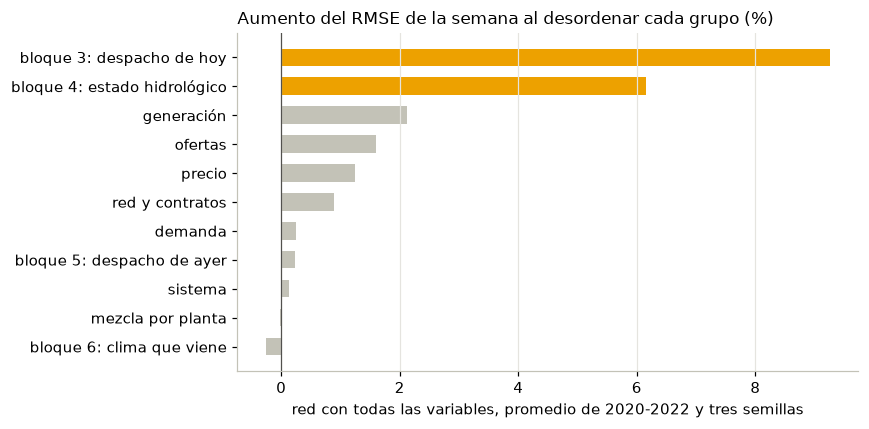

In [10]:
imp = pd.read_csv(LSTM / "importancia_grupos.csv").groupby("unidad")["aumento"].mean().sort_values()
elegidos = ["bloque 3: despacho de hoy", "bloque 4: estado hidrológico"]
nombre = {"generacion": "generación", "red_y_contratos": "red y contratos", "mezcla_por_planta": "mezcla por planta"}

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([nombre.get(u, u) for u in imp.index], imp, height=0.6,
        color=[COLOR["LSTM"] if u in elegidos else COLOR["ingenuo semanal"] for u in imp.index])
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_title("Aumento del RMSE de la semana al desordenar cada grupo (%)")
ax.set_xlabel("red con todas las variables, promedio de 2020-2022 y tres semillas")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Los dos grupos que más importan son justo los bloques 3 y 4. Ninguno de los grupos que quedaron
fuera de los bloques se les acerca, así que la tabla de bloques no dejó por fuera algo importante.

## 5. Hiperparámetros (2020-2022)

Búsqueda bayesiana (Snoek et al., 2012) de 30 configuraciones (10 al azar y 20 guiadas por las
anteriores), con el
conjunto de variables como un hiperparámetro más. Cada configuración se midió con una semilla en
los tres años de validación. Una sola corrida de la red es ruidosa, así que la búsqueda solo
propuso candidatas: las cinco mejores, junto con las configuraciones de la selección, se volvieron
a medir con tres semillas, y ganó la de menor RMSE de la semana.

In [11]:
print("Las 8 mejores de la búsqueda, con una semilla:")
display(pd.read_csv(LSTM / "busqueda.csv").head(8))
print("Candidatas con tres semillas:")
pd.read_csv(LSTM / "evaluacion_tres_semillas.csv").drop(columns="candidata")

Las 8 mejores de la búsqueda, con una semilla:


,configuracion,conjunto,capas,unidades,densa,dropout,tasa,lote,ventana,rmse_semana
0,01,b12_3_4,1,192,128,0.3,2.511e-03,64,56,0.244
1,"6c, selección primera",b12_3_4,1,128,64,0.2,1.000e-03,32,28,0.246
2,23,b12_3,2,192,128,0.2,6.105e-04,64,14,0.251
3,00,b12_3,2,256,128,0.2,6.696e-04,64,14,0.251
4,25,b12_3_4,2,360,32,0.3,5.558e-04,64,14,0.251
5,20,b12_3,2,192,128,0.3,3.432e-03,64,14,0.251
6,"6c, selección repetida",b12_3_4,2,192,128,0.5,2.803e-03,64,14,0.252
7,17,b12_3_4,1,32,128,0.4,4.001e-04,64,14,0.252


Candidatas con tres semillas:


,origen,conjunto,capas,unidades,densa,dropout,tasa,lote,ventana,rmse_semana,mejora_semana
0,"6c, selección primera",b12_3_4,1,128,64,0.2,1.000e-03,32,28,0.241,16.708
1,búsqueda 01,b12_3_4,1,192,128,0.3,2.511e-03,64,56,0.245,15.300
2,"6c, selección repetida",b12_3_4,2,192,128,0.5,2.803e-03,64,14,0.248,14.246
3,búsqueda 25,b12_3_4,2,360,32,0.3,5.558e-04,64,14,0.249,13.797
4,búsqueda 00,b12_3,2,256,128,0.2,6.696e-04,64,14,0.250,13.538
5,"6c, selección repetida",b12_3,2,192,128,0.5,2.803e-03,64,14,0.251,13.019
6,búsqueda 20,b12_3,2,192,128,0.3,3.432e-03,64,14,0.252,12.595
7,"6c, selección primera",b12_3,1,128,64,0.2,1.000e-03,32,28,0.252,12.590
8,búsqueda 23,b12_3,2,192,128,0.2,6.105e-04,64,14,0.253,12.389


Ganó la configuración fija con los bloques 3 y 4, que mejora 16,7% al ingenuo en la validación.
Las configuraciones de la búsqueda quedaron detrás al medirlas con tres semillas.

## 6. Validación y ensayo del test

La parada temprana deja fuera del entrenamiento el último 10% de los datos, justo los meses más
recientes. En el test eso no conviene, así que cada red se entrena con todo lo conocido durante un
número fijo de épocas. Antes de abrir el test se ensayó ese procedimiento en 2020-2022. La regla
era no abrir el test si el ensayo salía peor que la parada temprana con $p < 0{,}05$.

In [12]:
val = pd.read_csv(LSTM / "validacion_criterio.csv")
print(f"ensayo contra parada temprana: p = {cfg['ensayo_dm_p']:.3f}")
val.pivot(index="bloque", columns="procedimiento", values="mejora").loc[["h = 3 a 9", "h = 3", "h = 3 a 7", "h = 8 a 9"]]

ensayo contra parada temprana: p = 0.083


procedimiento,como en el test,parada temprana
bloque,,
h = 3 a 9,14.596,16.611
h = 3,23.413,23.485
h = 3 a 7,16.421,18.179
h = 8 a 9,11.595,14.023


El ensayo mejora 14,6% al ingenuo en la semana, frente a 16,6% con parada temprana. La diferencia
no es significativa ($p = 0{,}083$) y el test se abrió con ese procedimiento. Los dos números son
optimistas, porque 2020-2022 se usó para elegir los bloques y los hiperparámetros.

## 7. Test: 2023-2025 y 2026

El test se corrió una vez en Colab. Los pronósticos guardados tienen las mismas filas de XGBoost y
SARIMAX, así que el precio real y los ingenuos se toman de los archivos de XGBoost. El criterio es
el mismo: RMSE en logaritmo al menos 5% menor que el del mejor ingenuo y Diebold-Mariano
$p < 0{,}05$ (Diebold y Mariano, 1995).

In [13]:
BLOQUES = {"h = 3 a 9": HS, "h = 3": [3], "h = 3 a 7": [3, 4, 5, 6, 7], "h = 8 a 9": [8, 9]}


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))


def newey_west(d, L):
    # media de una serie diaria y su error estándar con L rezagos
    u = d - d.mean()
    v = np.mean(u * u)
    for l in range(1, min(L, len(d) - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * np.mean(u[l:] * u[:-l])
    return d.mean(), np.sqrt(v / len(d))


def diebold_mariano(e_a, e_b, fechas, L):
    # t negativo: a tiene menos error que b
    dif = np.square(np.asarray(e_a)) - np.square(np.asarray(e_b))
    d = pd.Series(dif).groupby(np.asarray(fechas)).mean().to_numpy()
    m, ee = newey_west(d, L)
    return m / ee, 2 * stats.norm.sf(abs(m / ee))


def criterio(g, pron="y_hat", bloques=BLOQUES):
    filas = []
    for nombre, hs in bloques.items():
        b = g[g["h"].isin(hs)]
        e = b["y"] - b[pron]
        ingenuos = {"del día": b["y"], "semanal": b["y"] - b["y_semanal"]}
        ref = min(ingenuos, key=lambda k: rmse(ingenuos[k]))
        t, p = diebold_mariano(e, ingenuos[ref], b["fecha"], max(hs) - 1 + 7)
        mejora = 100 * (1 - rmse(e) / rmse(ingenuos[ref]))
        filas.append({"bloque": nombre, "RMSE": rmse(e), "ingenuo": ref, "RMSE ingenuo": rmse(ingenuos[ref]),
                      "mejora (%)": mejora, "t": t, "p": p, "cumple": bool(mejora >= 5 and p < 0.05)})
    return pd.DataFrame(filas).set_index("bloque")

partes = [pd.read_csv(XGB / f"prueba_h{h}.csv.gz").assign(periodo="2023-2025") for h in HS]
partes.append(pd.read_csv(XGB / "prueba2026_mensual.csv.gz").query("3 <= h <= 9").assign(periodo="2026"))
xgb_test = pd.concat(partes, ignore_index=True)

lstm = pd.concat([pd.read_csv(LSTM / "prueba_2023_2025.csv.gz").assign(periodo="2023-2025"),
                  pd.read_csv(LSTM / "prueba_2026.csv.gz").assign(periodo="2026")])
d = lstm.merge(xgb_test[["periodo", "fecha", "hora", "h", "precio_t", "y", "y_semanal"]],
               on=["periodo", "fecha", "hora", "h"], validate="one_to_one")
assert len(d) == len(lstm) == len(xgb_test)
d["fecha"] = pd.to_datetime(d["fecha"])
print(f"{len(d):,} pronósticos, en las mismas filas de XGBoost y SARIMAX")
pd.concat({p: criterio(g) for p, g in d.groupby("periodo")}, names=["periodo"])

228,984 pronósticos, en las mismas filas de XGBoost y SARIMAX


RMSE  ingenuo  RMSE ingenuo  mejora (%)      t  \
periodo   bloque                                                       
2023-2025 h = 3 a 9  0.427  del día         0.502      14.880 -4.617   
          h = 3      0.310  del día         0.411      24.547 -8.783   
          h = 3 a 7  0.389  del día         0.472      17.478 -5.604   
          h = 8 a 9  0.509  del día         0.570      10.585 -3.026   
2026      h = 3 a 9  0.350  del día         0.435      19.711 -3.659   
          h = 3      0.254  del día         0.352      27.925 -4.562   
          h = 3 a 7  0.320  del día         0.409      21.620 -3.930   
          h = 8 a 9  0.414  del día         0.496      16.537 -3.083   

                             p  cumple  
periodo   bloque                        
2023-2025 h = 3 a 9  3.889e-06    True  
          h = 3      1.596e-18    True  
          h = 3 a 7  2.091e-08    True  
          h = 8 a 9  2.475e-03    True  
2026      h = 3 a 9  2.533e-04    True  
          h = 3      5.079e-06    True  
          h = 3 a 7  8.490e-05    True  
          h = 8 a 9  2.047e-03    True

La LSTM cumple el criterio en todos los bloques y en los dos periodos: 14,9% de mejora en la semana
completa en 2023-2025 y 19,7% en 2026. En $h = 3$ la mejora es de 24,5% y 27,9%.

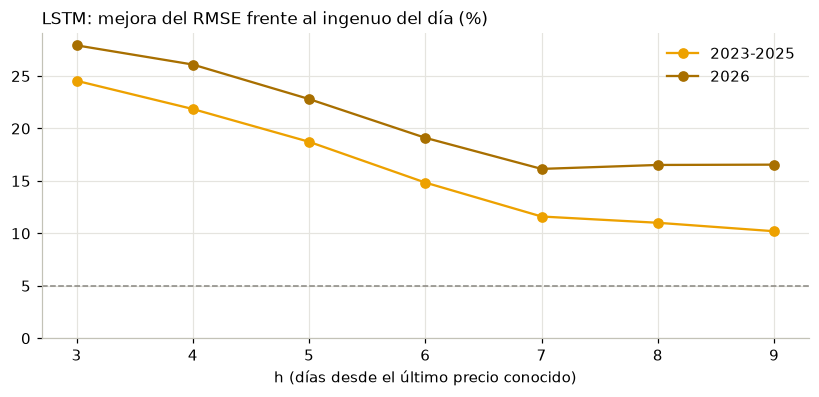

periodo,2023-2025,2026
h,,
3,24.5,27.9
4,21.9,26.1
5,18.7,22.8
6,14.8,19.1
7,11.6,16.1
8,11.0,16.5
9,10.2,16.6


,RMSE,RMSE ingenuo,mejora (%),p,cumple
año,,,,,
2023,0.427,0.544,21.566,2.393e-05,True
2024,0.459,0.508,9.747,9.841e-02,False
2025,0.393,0.447,12.224,6.842e-03,True


In [14]:
por_h = (d.groupby(["periodo", "h"])
         .apply(lambda g: 100 * (1 - rmse(g["y"] - g["y_hat"]) / rmse(g["y"])), include_groups=False)
         .unstack("periodo"))

fig, ax = plt.subplots(figsize=(9, 3.6))
for periodo, color in [("2023-2025", COLOR["LSTM"]), ("2026", "#a86f00")]:
    ax.plot(HS, por_h[periodo], marker="o", color=color, label=periodo)
ax.axhline(5, color="#898781", ls="--", lw=1)
ax.set_ylim(bottom=0)
ax.set_title("LSTM: mejora del RMSE frente al ingenuo del día (%)")
ax.set_xlabel("h (días desde el último precio conocido)")
ax.legend()
plt.show()

t = d[d["periodo"] == "2023-2025"]
por_año = pd.concat({a: criterio(g, bloques={"h = 3 a 9": HS}) for a, g in t.groupby(t["fecha"].dt.year)},
                    names=["año"]).droplevel("bloque")
display(por_h.round(1))
por_año[["RMSE", "RMSE ingenuo", "mejora (%)", "p", "cumple"]]

La mejora es mayor en los primeros días y baja con el horizonte, pero se mantiene por encima de 10%
hasta $h = 9$, y no tiene la caída de $h = 7$ que se ve en SARIMAX y XGBoost. En 2026 la mejora es
mayor que en 2023-2025 en todos los horizontes.

Por años, 2023 es el mejor (21,6%). En 2024 la mejora es 9,7% pero no es significativa
($p = 0{,}098$), lo mismo que le pasa a XGBoost ese año.

### Resultados con el formato de Salazar-Peña et al. (2025)

Como en los otros dos modelos, los resultados también se presentan con el formato de
Salazar-Peña et al. (2025): MAE, RMSE, nRMSE (el RMSE dividido por el promedio real), MBE (el
error medio) y MAPE por horizonte, en COP/kWh y con un intervalo t al 95%, y el MAPE por hora del
día. El pronóstico en pesos es $\hat P = P(t,H)\,e^{\hat y}$ y el skill score es la mejora del
RMSE en pesos frente al ingenuo del día.

In [15]:
# El error es pronóstico menos real, en COP/kWh: un MBE negativo quiere decir que el modelo
# se quedó por debajo del precio real.
AZULES = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#256abf", "#184f95", "#0d366b"]
COLOR_METRICA = {"MAE": "#5598e7", "RMSE": "#0d366b", "MBE": "#52514e"}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
EJE_H = "h (días desde el último precio conocido)"


def metricas(g, pron):
    e = g[pron] - g["real"]
    r = np.sqrt(np.mean(e ** 2))
    return pd.Series({"MAE": e.abs().mean(), "RMSE": r, "nRMSE (%)": 100 * r / g["real"].mean(),
                      "MBE": e.mean(), "MAPE (%)": 100 * (e.abs() / g["real"]).mean()})


def por_horizonte(g, pron):
    # el intervalo t al 95% se calcula con el error promedio de cada día de pronóstico,
    # porque las 24 horas de un mismo día no son independientes
    filas = {}
    for h, x in g.groupby("h"):
        e = x[pron] - x["real"]
        dia = pd.DataFrame({"MAE": e.abs(), "MBE": e, "MSE": e ** 2}).groupby(x["fecha"]).mean()
        media = dia.mean()
        margen = stats.t.ppf(0.975, len(dia) - 1) * dia.std() / np.sqrt(len(dia))
        f = {}
        for m in ["MAE", "MBE", "MSE"]:
            f[m], f[m + " inf"], f[m + " sup"] = media[m], media[m] - margen[m], media[m] + margen[m]
        for c in ["", " inf", " sup"]:
            f["RMSE" + c] = np.sqrt(max(f["MSE" + c], 0))
            f["nRMSE" + c] = 100 * f["RMSE" + c] / x["real"].mean()
        f["MAPE"] = 100 * (e.abs() / x["real"]).mean()
        filas[h] = f
    return pd.DataFrame(filas).T


def figura_error(tablas, modelo):
    # como las figuras 15, 18 y 21 del paper
    fig, ejes = plt.subplots(1, len(tablas), figsize=(11, 3.8), sharey=True)
    for ax, (periodo, r) in zip(ejes, tablas.items()):
        ax.axhline(0, color="#898781", lw=0.8)
        for m in ["MAE", "RMSE", "MBE"]:
            ax.errorbar(r.index, r[m], yerr=[r[m] - r[m + " inf"], r[m + " sup"] - r[m]], color=COLOR_METRICA[m],
                        marker="o", ms=4, capsize=3, label=m)
        ax.set_title(periodo)
        ax.set_xticks(HS)
        ax.set_xlabel(EJE_H)
    ejes[0].set_ylabel("COP/kWh")
    ejes[0].legend()
    fig.suptitle(f"{modelo}: error por horizonte, con intervalo de 95%", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def figura_nrmse(tablas, colores, modelo):
    # como las figuras 16, 19 y 22 del paper
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for periodo, r in tablas.items():
        ax.plot(r.index, r["nRMSE"], color=colores[periodo], marker="o", ms=4, label=periodo)
        ax.fill_between(r.index, r["nRMSE inf"], r["nRMSE sup"], color=colores[periodo], alpha=0.2, lw=0)
    ax.set_xticks(HS)
    ax.set_xlabel(EJE_H)
    ax.set_ylabel("%")
    ax.set_title(f"{modelo}: nRMSE por horizonte, con intervalo de 95%")
    ax.legend()
    plt.show()


def figura_mape_hora(g, pron, modelo):
    # como las figuras 17, 20 y 23 del paper: una curva por horizonte, de h = 3 (clara) a h = 9 (oscura)
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, (periodo, x) in zip(ejes, g.groupby("periodo")):
        mape = (100 * (x[pron] - x["real"]).abs() / x["real"]).groupby([x["hora"], x["h"]]).mean().unstack("h")
        for h, c in zip(HS, AZULES):
            ax.plot(mape.index, mape[h], color=c, lw=1.5, label=f"h = {h}")
        ax.set_title(periodo)
        ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
        ax.set_xlabel("hora del día")
    ejes[0].set_ylabel("MAPE (%)")
    ejes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"{modelo}: MAPE por hora del día y horizonte", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


def figura_semana(s, columnas, titulo):
    # como las figuras 28 a 37 del paper: el pronóstico frente al real y su correlación de Pearson
    s = s.sort_values("momento")
    previo = s.drop_duplicates("hora").sort_values("hora")
    momento_previo = previo["t"] + pd.to_timedelta(previo["hora"] - 1, unit="h")
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.6, 1]})
    a1.plot(momento_previo, previo["ingenuo del día"], color="#52514e", lw=1.3, label="último día conocido")
    a1.plot(s["momento"], s["real"], color=COLOR["precio real"], lw=2, label="precio real")
    for c in columnas:
        estilo = {"ls": "--", "lw": 1.1} if c.startswith("ingenuo") else {"lw": 1.4}
        a1.plot(s["momento"], s[c], color=COLOR[c], label=c, **estilo)
        r = np.corrcoef(s["real"], s[c])[0, 1]
        a2.scatter(s[c], s["real"], s=8, color=COLOR[c], alpha=0.7, label=f"{c}, r = {r:.2f}".replace(".", ","))
    lim = [s[columnas + ["real"]].min().min(), s[columnas + ["real"]].max().max()]
    a2.plot(lim, lim, color="#898781", lw=0.8)
    dias = pd.date_range(previo["t"].iloc[0], s["momento"].max().normalize())
    a1.set_xticks(dias, [f"{x.day} {MESES[x.month - 1]}" for x in dias])
    a1.set_ylabel("COP/kWh")
    a1.set_title(titulo)
    a1.legend(ncol=3, fontsize=8)
    a2.set_xlabel("pronóstico (COP/kWh)")
    a2.set_ylabel("precio real (COP/kWh)")
    a2.set_title("Pronóstico frente al real")
    a2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

pesos = d.assign(real=d["precio_t"] * np.exp(d["y"]), LSTM=d["precio_t"] * np.exp(d["y_hat"]),
                 **{"ingenuo del día": d["precio_t"]})
semana = pd.DataFrame({(p, m): metricas(g, m) for p, g in pesos.groupby("periodo")
                       for m in ["LSTM", "ingenuo del día"]}).T
ref = semana.xs("ingenuo del día", level=1)["RMSE"]
semana["skill score (%)"] = 100 * (1 - semana["RMSE"] / ref.reindex(semana.index.get_level_values(0)).to_numpy())
semana.round(1)

MAE   RMSE  nRMSE (%)   MBE  MAPE (%)  \
2023-2025 LSTM             138.9  238.9       48.6 -33.1      34.1   
          ingenuo del día  150.1  257.1       52.3   1.3      40.1   
2026      LSTM             114.5  172.0       35.2 -30.6      25.6   
          ingenuo del día  127.1  188.5       38.6  -8.3      32.4   

                           skill score (%)  
2023-2025 LSTM                         7.1  
          ingenuo del día              0.0  
2026      LSTM                         8.8  
          ingenuo del día              0.0

En pesos la LSTM también le gana al ingenuo en todas las métricas menos el MBE: en 2023-2025 su
MAE es 139 COP/kWh frente a 150 y su MAPE 34,1% frente a 40,1%. El skill score de la semana es
7,1% en 2023-2025 y 8,8% en 2026, menos que la mejora en logaritmo (14,9% y 19,7%). La red se
queda corta en promedio, unos 33 COP/kWh en 2023-2025: se entrenó para el error en logaritmo, y al
volver a pesos $e^{\hat y}$ se acerca a la mediana del precio, que queda por debajo de la media
porque el precio tiene picos hacia arriba (Duan, 1983).

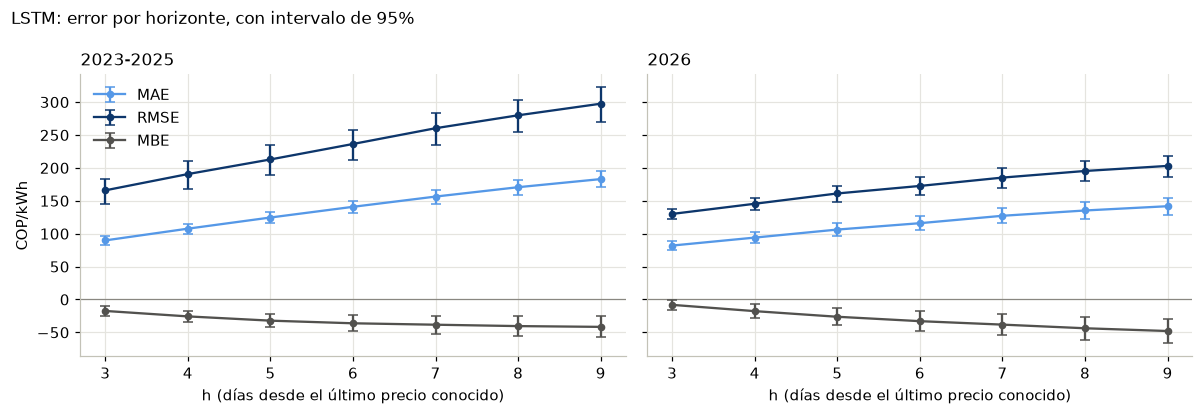

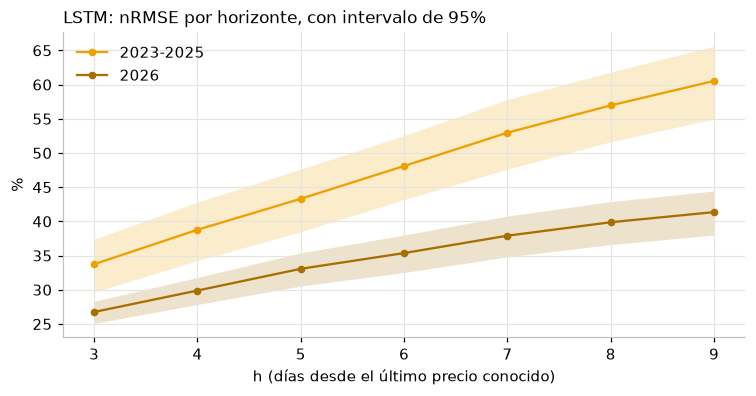

2023-2025                            2026                         
        MAE   RMSE nRMSE   MBE  MAPE    MAE   RMSE nRMSE   MBE  MAPE
3      89.8  165.9  33.7 -17.4  21.6   81.9  130.0  26.8  -8.2  18.2
4     107.6  190.6  38.8 -25.7  26.1   94.1  145.5  29.9 -17.7  20.8
5     124.6  212.8  43.3 -32.2  30.3  106.3  161.1  33.1 -26.3  23.6
6     140.8  236.3  48.1 -36.2  34.2  116.0  172.6  35.4 -33.0  26.0
7     156.4  260.3  53.0 -38.4  38.1  127.2  185.2  37.9 -38.2  28.7
8     170.7  279.9  57.0 -40.5  42.3  135.3  195.3  39.9 -43.8  30.4
9     183.0  297.6  60.5 -41.6  45.9  141.8  203.0  41.4 -47.9  31.9

In [16]:
tablas = {p: por_horizonte(g, "LSTM") for p, g in pesos.groupby("periodo")}
figura_error(tablas, "LSTM")
figura_nrmse(tablas, {"2023-2025": COLOR["LSTM"], "2026": "#a86f00"}, "LSTM")
pd.concat({p: r[["MAE", "RMSE", "nRMSE", "MBE", "MAPE"]] for p, r in tablas.items()}, axis=1).round(1)

El error crece con el horizonte: en 2023-2025 el MAE va de 90 COP/kWh en $h = 3$ a 183 en $h = 9$,
y el nRMSE de 34% a 61%. El MBE es negativo en todos los horizontes y crece de $-17$ a $-42$
COP/kWh, sin que el intervalo toque el cero. Por eso, en pesos, la ventaja frente al ingenuo se
concentra en los primeros días: el skill score baja de 20% en $h = 3$ a casi cero en $h = 9$. En
2026 el nRMSE va de 27% a 41% y el skill score queda entre 3% y 20%.

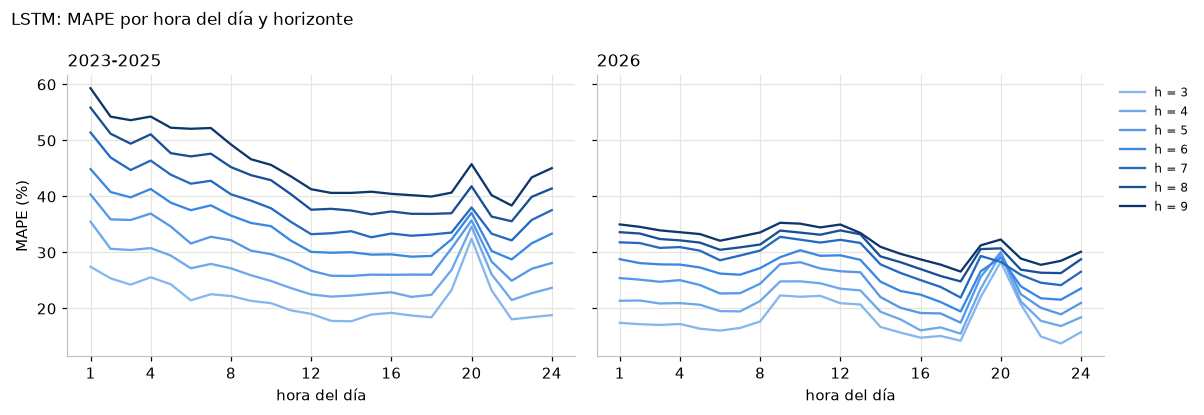

In [17]:
figura_mape_hora(pesos, "LSTM", "LSTM")

El MAPE crece con el horizonte en casi todas las horas. En 2023-2025 el más alto está en la
madrugada (hora 1) y hay un segundo pico en la hora 20, la del pico de la noche: en $h = 3$ es la
hora con más error (32,5%), mientras en la tarde baja hasta 17,7% (hora 14). En 2026 la hora 20
también es de las de más error.

### Semana del 9 al 15 de octubre de 2026

Pronóstico con los precios conocidos hasta el 6 de octubre. Es una sola semana: muestra cómo se
comporta la red, no la evalúa.

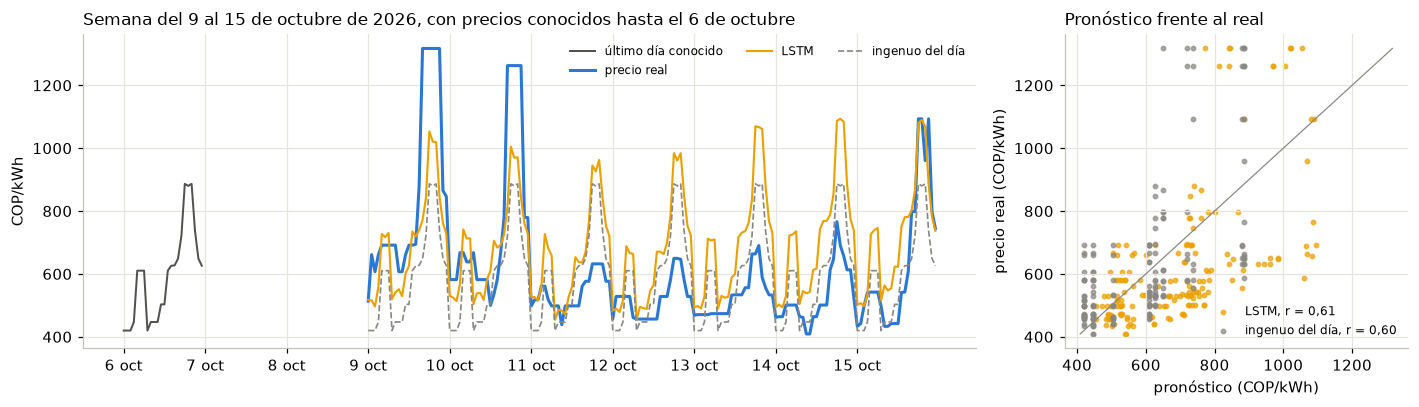

,LSTM,ingenuo del día
RMSE en log,0.252,0.234
MAPE (%),23.220,18.715
MBE (COP/kWh),66.805,-31.991
r de Pearson,0.611,0.599


In [18]:
fin_l = pd.read_csv(LSTM / "pronostico_final.csv", parse_dates=["origen", "fecha_objetivo"])
real = pd.read_csv(XGB / "precio_real_final.csv", parse_dates=["fecha_objetivo"])
sem = (fin_l.merge(real, on=["fecha_objetivo", "hora"])
       .rename(columns={"origen": "t", "precio_real": "real", "precio_pron": "LSTM",
                        "precio_t": "ingenuo del día"}))
sem["momento"] = sem["fecha_objetivo"] + pd.to_timedelta(sem["hora"] - 1, unit="h")
figura_semana(sem, ["LSTM", "ingenuo del día"],
              "Semana del 9 al 15 de octubre de 2026, con precios conocidos hasta el 6 de octubre")

pd.DataFrame({m: {"RMSE en log": rmse(np.log(sem["real"] / sem[m])),
                  "MAPE (%)": 100 * np.mean(np.abs(sem[m] / sem["real"] - 1)),
                  "MBE (COP/kWh)": np.mean(sem[m] - sem["real"]),
                  "r de Pearson": np.corrcoef(sem["real"], sem[m])[0, 1]}
              for m in ["LSTM", "ingenuo del día"]}).round(3)

La red pronosticó para toda la semana precios entre 10% y 20% por encima del último conocido. Los
dos primeros días el precio subió todavía más, pero del 11 al 14 de octubre bajó y la red quedó
por encima: su MBE en la semana fue positivo, de 67 COP/kWh. Tuvo más error que el ingenuo del día
(0,252 frente a 0,234 en RMSE en logaritmo y MAPE de 23,2% frente a 18,7%), con una correlación
con el precio real parecida (0,61 frente a 0,60).

## Hallazgos

1. La LSTM cumple el criterio en todos los bloques y en los dos periodos, con la mayor mejora de
   los tres modelos: 14,9% en 2023-2025 y 19,7% en 2026 en la semana completa, y 24,5% y 27,9% en
   $h = 3$.
2. Lo que más aporta es el despacho programado del día $R$ (bloque 3), que se conoce antes que el
   precio. Con solo precio y calendario la red mejora 4,2% en la validación y con el despacho de
   hoy sube a 12,6%. También es el grupo que más sube el error cuando se desordena.
3. Más variables no ayudan: con las 136 del panel la red mejora 9,0%, frente a 16,7% con las 9
   elegidas.
4. La red es sensible a la configuración y a la semilla. Las dos selecciones no coincidieron en el
   bloque hidrológico, y por eso las decisiones se tomaron con el promedio de tres semillas.
5. La mejora cambia entre años: en 2024 (9,7%) no es significativa, como pasa con XGBoost.
6. En la semana del 9 al 15 de octubre la red tuvo más error que el ingenuo. La ventaja promedio no
   se cumple todas las semanas.
7. En pesos, con el formato de Salazar-Peña et al. (2025), la red también tiene menos error que el
   ingenuo (MAE de 139 frente a 150 COP/kWh y MAPE de 34,1% frente a 40,1% en 2023-2025), pero se
   queda corta en promedio (MBE de $-33$ COP/kWh) y su skill score baja de 20% en $h = 3$ a casi
   cero en $h = 9$.

## Referencias

- Diebold, F. y Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253-263.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605-610.
- Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735-1780.
- Salazar-Peña, N., Palma-Vergara, A., Montes-Vera, M., Vargas-Torres, M. A., Hernández Vanegas, R., Amador, M., Rojas, B., Salinas, A., Velasco, A., Tabares, A. y González-Mancera, A. (2025). Intra-day solar and power forecast for optimization of intraday market participation. *arXiv*, 2501.09551v3.
- Snoek, J., Larochelle, H. y Adams, R. (2012). Practical Bayesian optimization of machine learning algorithms. En *Advances in Neural Information Processing Systems 25* (pp. 2951-2959).
- Sutskever, I., Vinyals, O. y Le, Q. (2014). Sequence to sequence learning with neural networks. En *Advances in Neural Information Processing Systems 27* (pp. 3104-3112).